# EMQA_L1_merit_opcom

**The merit order on real OPCOM day-ahead curves**

Energy Markets Quantitative Analysis (EMQA), Lecture 1 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L1/EMQA_L1_merit_opcom/EMQA_L1_merit_opcom.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

Aggregated supply and demand curves of the Romanian day-ahead market (OPCOM PZU) for one delivery day, midday (12:00-12:15) and evening (20:00-20:15) quarter-hours, with the official clearing price: the price is set where the curves cross.

**Data:** 2026-10-21, Romanian time; quantities include blocks, hourly orders and net flows. **Source:** OPCOM, PZU aggregated curves.

The numbers printed below are those on the slide; the tag `[key]` is their name in `lectures/L1/L1_numbers.json`.

In [2]:
import json
import urllib.request
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}   # fixed colour per bidding zone
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
ZONE_LS = {'RO': '-', 'BG': '--', 'HU': '-.', 'DE_LU': ':'}
ZONES = ['RO', 'BG', 'HU', 'DE_LU']
ZONE_NAME = {'RO': 'Romania (OPCOM PZU)', 'BG': 'Bulgaria (IBEX)', 'HU': 'Hungary (HUPX)', 'DE_LU': 'Germany-Luxembourg'}
MON_EN = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
ZONE_SHORT = {'RO': 'RO (OPCOM PZU)', 'BG': 'BG (IBEX)', 'HU': 'HU (HUPX)', 'DE_LU': 'DE-LU (EPEX SPOT)'}


def month_ticks(ax, step=1):
    """Month axis 1..12: every month named, written vertically so it fits."""
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels([MON_EN[m - 1] if (m - 1) % step == 0 else '' for m in range(1, 13)], fontsize=9, rotation=90)


def legend_bottom(fig, ncol=4, y=0.0):
    """One legend centred under the axes, outside the plotting area."""
    handles, labels = [], []
    for ax in fig.axes:
        for h, l_ in zip(*ax.get_legend_handles_labels()):
            if l_ not in labels:
                handles.append(h)
                labels.append(l_)
    if handles:
        fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, y), frameon=False,
                   handlelength=2.0, columnspacing=1.2)


def fl(x, k=4):
    """Round as on the slides."""
    return None if x is None or np.isnan(float(x)) else round(float(x), k)


def d(ts):
    return pd.Timestamp(ts).strftime('%Y-%m-%d')


def show(key, label, value):
    """Print a number of the slide; [key] = its name in lectures/L1/L1_numbers.json."""
    print(f'{label} = {value}   [{key}]')

## Computation

In [3]:
CURVES = pd.read_csv(DATA + 'opcom_pzu_curves.csv')
meta_path = DATA + 'opcom_pzu_curves_meta.json'
CMETA = json.load(urllib.request.urlopen(meta_path)) if meta_path.startswith('http') else json.load(open(meta_path))
day = CURVES['delivery_date'].iloc[0]
M = {}
for iv in CMETA['intervals']:
    k = 'mid' if iv['opcom_interval'] == 45 else 'eve'
    s = CURVES[(CURVES['interval'] == iv['interval_label']) & (CURVES['side'] == 'supply')]
    M[k] = {'label': iv['interval_label'], 'price': iv['official_clearing_price_eur_mwh'], 'q': iv['curve_cleared_quantity_mw'],
            'q_le0': fl(s.loc[s['price_eur_mwh'] <= 0, 'quantity_mw'].max(), 0), 'net_imp': fl(-iv['net_export_mw'], 0)}
show('merit.day', 'delivery day', day)
for k in ['mid', 'eve']:
    show(f'merit.{k}.price', f'{k}: clearing price, EUR/MWh', M[k]['price'])
    show(f'merit.{k}.q_le0', f'{k}: supply offered at a price <= 0, MW', M[k]['q_le0'])
    show(f'merit.{k}.net_imp', f'{k}: net imports in the supply, MW', M[k]['net_imp'])

delivery day = 2026-10-21   [merit.day]
mid: clearing price, EUR/MWh = 152.23   [merit.mid.price]
mid: supply offered at a price <= 0, MW = 2333.0   [merit.mid.q_le0]
mid: net imports in the supply, MW = -48.0   [merit.mid.net_imp]
eve: clearing price, EUR/MWh = 244.0   [merit.eve.price]
eve: supply offered at a price <= 0, MW = 3033.0   [merit.eve.q_le0]
eve: net imports in the supply, MW = 1054.0   [merit.eve.net_imp]


## Chart

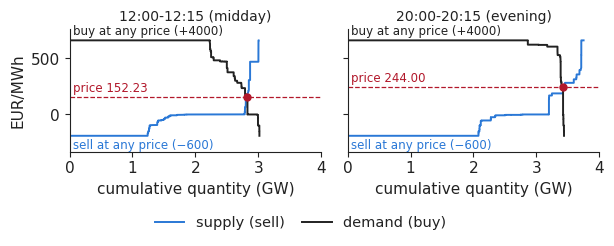

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(6.4, 2.5), sharey=True)
for ax, k in zip(axs, ['mid', 'eve']):
    m = M[k]
    for side, col, lab in [('supply', PAL['RO'], 'supply (sell)'), ('demand', '#222222', 'demand (buy)')]:
        c = CURVES[(CURVES['interval'] == m['label']) & (CURVES['side'] == side)]
        ax.plot(c['quantity_mw'] / 1000, c['price_eur_mwh'].clip(-190, 660), color=col, lw=1.4, label=lab)
    ax.axhline(m['price'], color='#b2182b', ls='--', lw=0.9)
    ax.plot([m['q'] / 1000], [m['price']], 'o', color='#b2182b', ms=5)
    ax.annotate(f"price {m['price']:.2f}", (0.05, m['price']), textcoords='offset points', xytext=(0, 4), fontsize=8.5,
                color='#b2182b')
    ax.set_title({'mid': '12:00-12:15 (midday)', 'eve': '20:00-20:15 (evening)'}[k], fontsize=10)
    ax.set_ylim(-330, 760)
    ax.set_xlim(0, 4)
    # the curves are clipped at -190 and 660 EUR/MWh: the labels sit just outside the clipped lines, clear of the curves
    ax.text(0.05, -215, 'sell at any price (−600)', fontsize=8.5, color=PAL['RO'], va='top')
    ax.text(0.05, 685, 'buy at any price (+4000)', fontsize=8.5, color='#222222', va='bottom')
    ax.set_xlabel('cumulative quantity (GW)')
axs[0].set_ylabel('EUR/MWh')
legend_bottom(fig, ncol=2)
fig.tight_layout(rect=(0, 0.12, 1, 1))
plt.savefig('merit_opcom.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()